# BigBird: Sparse Attention for Long Sequences

BigBird (Zaheer et al., Google Research, NeurIPS 2020) is a Transformer encoder that replaces full self-attention with a **sparse** pattern. The pattern makes cost grow **linearly** with sequence length while keeping the theoretical properties of full attention.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import shortest_path

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

## 1. The quadratic bottleneck

In standard self-attention (BERT, RoBERTa), every token attends to every other token. For sequence length $n$ and hidden size $d$:

- **Time:** $O(n^2 \cdot d)$
- **Memory:** $O(n^2)$ for the attention matrix, per head and per layer

At $n = 512$ this is fine. At $n = 4096$ the attention matrix has about 16.7M entries per head per layer, so memory runs out quickly. In practice BERT-style models are capped at 512 tokens, and long documents must be truncated or chunked. Chunking loses cross-chunk context, which hurts tasks like multi-hop QA, long-document summarization, and genomics.

**Goal of BigBird:** process roughly 8x longer sequences (4096+) on the same hardware without losing the expressive power that makes full attention work.

      n |  scores per head/layer |  memory (fp16)
----------------------------------------------------
    512 |                 0.3 M |         0.5 MB
   1024 |                 1.0 M |         2.1 MB
   2048 |                 4.2 M |         8.4 MB
   4096 |                16.8 M |        33.6 MB
   8192 |                67.1 M |       134.2 MB
  16384 |               268.4 M |       536.9 MB


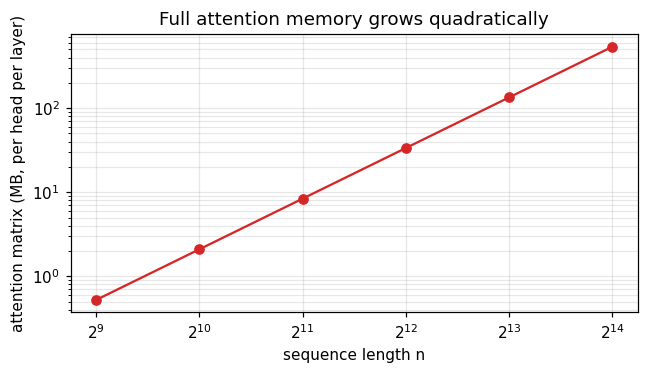

In [2]:
ns = np.array([512, 1024, 2048, 4096, 8192, 16384])
bytes_per_score = 2  # fp16

print(f"{'n':>7} | {'scores per head/layer':>22} | {'memory (fp16)':>14}")
print("-" * 52)
for n in ns:
    scores = n * n
    print(f"{n:>7} | {scores/1e6:>19.1f} M | {scores*bytes_per_score/1e6:>11.1f} MB")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ns, ns**2 * bytes_per_score / 1e6, "o-", color="tab:red")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("sequence length n"); ax.set_ylabel("attention matrix (MB, per head per layer)")
ax.set_title("Full attention memory grows quadratically")
ax.grid(True, which="both", alpha=.3)
plt.tight_layout(); plt.show()

## 2. Architecture and key innovations

BigBird views attention as a **graph**: tokens are nodes, and an edge means "can attend to." Full attention is a complete graph. BigBird uses a sparse graph built from three components.

### Sliding-window attention
Each token attends to $w$ neighbors on each side. This captures local context, which dominates in language, and is the same idea Longformer uses.

### Global tokens
A small set of $g$ tokens attend to everything and are attended to by everything. They act as information hubs, so any two tokens can exchange information in two hops. There are two variants:

- **ITC (Internal Transformer Construction):** existing tokens (such as `[CLS]`) are made global.
- **ETC (Extended Transformer Construction):** extra auxiliary global tokens are added, which gives more capacity and works well for structured tasks like QA.

### Random attention
Each token attends to $r$ randomly chosen tokens. This is BigBird's distinctive contribution. Random graphs have two useful properties:

- They have a short average path length of about $O(\log n)$, so information spreads across the sequence quickly.
- Their spectral properties approximate those of a complete graph.

Together, window, global, and random edges give a **small-world graph**: local structure plus long-range shortcuts.

The cell below builds each component at the token level and shows them side by side.

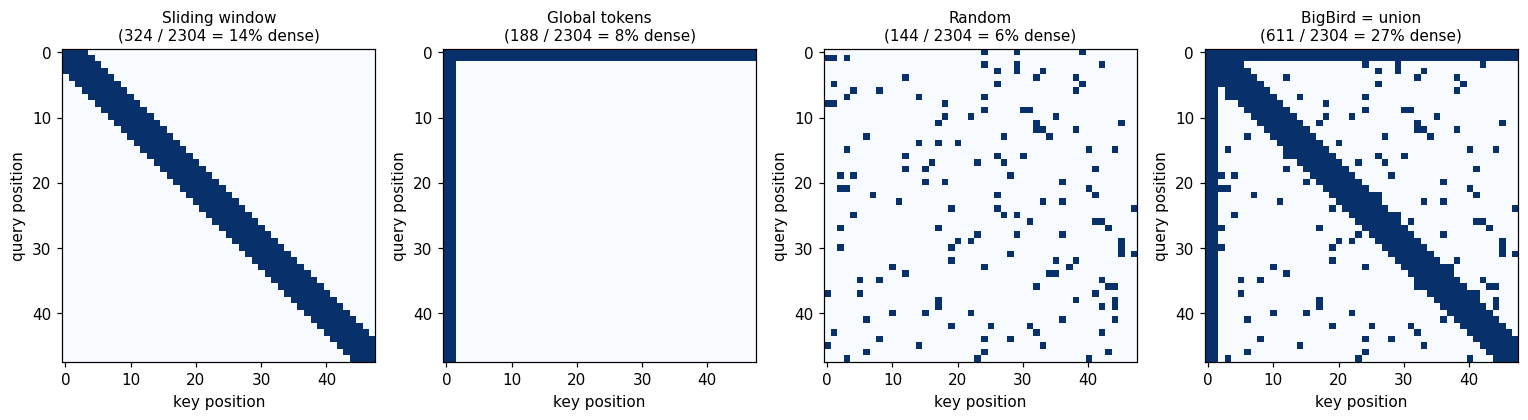

In [3]:
def token_components(n, window=3, n_global=2, n_random=3, seed=0):
    # Return boolean (n x n) masks for window, global, random. M[i, j] = True means i attends to j.
    rng = np.random.default_rng(seed)
    W = np.zeros((n, n), bool)
    for i in range(n):
        W[i, max(0, i - window): min(n, i + window + 1)] = True

    G = np.zeros((n, n), bool)
    G[:n_global, :] = True   # global tokens attend to everything
    G[:, :n_global] = True   # everything attends to global tokens

    R = np.zeros((n, n), bool)
    for i in range(n):
        R[i, rng.choice(n, n_random, replace=False)] = True
    return W, G, R


def show_masks(masks, titles, figsize=(14, 3.6)):
    fig, axes = plt.subplots(1, len(masks), figsize=figsize)
    for ax, m, t in zip(axes, masks, titles):
        ax.imshow(m, cmap="Blues", interpolation="nearest")
        ax.set_title(f"{t}\n({m.sum()} / {m.size} = {m.mean():.0%} dense)", fontsize=10)
        ax.set_xlabel("key position"); ax.set_ylabel("query position")
    plt.tight_layout(); plt.show()


n = 48
W, G, R = token_components(n, window=3, n_global=2, n_random=3)
show_masks([W, G, R, W | G | R],
           ["Sliding window", "Global tokens", "Random", "BigBird = union"])

### A tiny attention implementation with a mask

The function below applies a mask to ordinary scaled dot-product attention. This is only to illustrate *which* scores survive. It still computes the dense matrix, whereas a real BigBird implementation never materializes the masked-out entries.

In [4]:
def masked_attention(Q, K, V, mask):
    scores = Q @ K.T / np.sqrt(Q.shape[-1])
    scores = np.where(mask, scores, -np.inf)
    scores -= scores.max(axis=-1, keepdims=True)
    probs = np.exp(scores)
    probs /= probs.sum(axis=-1, keepdims=True)
    return probs @ V, probs


rng = np.random.default_rng(1)
d = 16
Q, K, V = (rng.normal(size=(n, d)) for _ in range(3))

full_out, _ = masked_attention(Q, K, V, np.ones((n, n), bool))
sparse_out, sparse_p = masked_attention(Q, K, V, W | G | R)

print("Non-zero attention weights per query (sparse):", int((sparse_p > 0).sum(axis=1).mean()), "of", n)
print("Rows sum to 1:", np.allclose(sparse_p.sum(axis=1), 1))
print("Mean |full - sparse| output difference:", float(np.abs(full_out - sparse_out).mean()))

Non-zero attention weights per query (sparse): 12 of 48
Rows sum to 1: True
Mean |full - sparse| output difference: 0.295576755295835


## 3. Block-sparse implementation

Truly random, per-token edges are slow on GPUs and TPUs because they need irregular memory gathers. BigBird therefore works on **blocks** of tokens (for example, block size 64):

- The sequence is split into $n/b$ blocks.
- Each query block attends to a fixed number of key blocks: sliding blocks, global blocks, and random blocks.
- Attention becomes a small number of **dense** matrix multiplications, which hardware handles efficiently.

In a common configuration (block size 64, 3 window blocks, 2 global blocks, 3 random blocks), each query attends to 8 blocks, or 512 keys. That is the same per-token attention budget as BERT's full 512-token context, but spread across a 4096-token sequence.

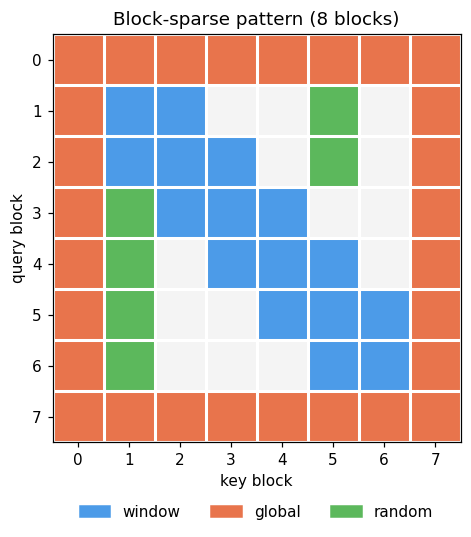

Key blocks attended per query block: [8, 5, 6, 6, 6, 6, 5, 8]


In [5]:
def block_mask(n_blocks, window_blocks=3, n_random=1, seed=0):
    # Block-level mask: first and last blocks are global (as in the ITC setup).
    rng = np.random.default_rng(seed)
    M = np.zeros((n_blocks, n_blocks), int)   # 0 none, 1 window, 2 global, 3 random
    half = window_blocks // 2
    for i in range(n_blocks):
        M[i, max(0, i - half): min(n_blocks, i + half + 1)] = 1
        # random blocks: pick from blocks not already attended
        candidates = [j for j in range(n_blocks)
                      if M[i, j] == 0 and j not in (0, n_blocks - 1)]
        if candidates:
            pick = rng.choice(candidates, min(n_random, len(candidates)), replace=False)
            M[i, pick] = 3
    M[[0, -1], :] = 2   # global rows
    M[:, [0, -1]] = 2   # global columns
    return M


from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

nb_ = 8
BM = block_mask(nb_, window_blocks=3, n_random=1)
cmap = ListedColormap(["#f4f4f4", "#4C9BE8", "#E8744C", "#5CB85C"])

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.imshow(BM, cmap=cmap, vmin=0, vmax=3)
ax.set_xticks(range(nb_)); ax.set_yticks(range(nb_))
ax.set_xticks(np.arange(-.5, nb_, 1), minor=True); ax.set_yticks(np.arange(-.5, nb_, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
ax.set_xlabel("key block"); ax.set_ylabel("query block")
ax.set_title("Block-sparse pattern (8 blocks)")
ax.legend(handles=[Patch(color="#4C9BE8", label="window"),
                   Patch(color="#E8744C", label="global"),
                   Patch(color="#5CB85C", label="random")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

print("Key blocks attended per query block:", (BM > 0).sum(axis=1).tolist())

In [6]:
# Per-token budget for the common BigBird configuration
block_size, window_blocks, global_blocks, random_blocks = 64, 3, 2, 3
keys_per_query = block_size * (window_blocks + global_blocks + random_blocks)
print("Keys attended per query token:", keys_per_query)
print("At n = 4096, fraction of full attention computed:", f"{keys_per_query / 4096:.1%}")

Keys attended per query token: 512
At n = 4096, fraction of full attention computed: 12.5%


### Theoretical guarantees

The paper proves that sparse attention with global tokens is a **universal approximator** of sequence-to-sequence functions and is **Turing complete**. It also shows a limitation: some tasks that full attention solves in $O(1)$ layers provably need more layers under sparse attention. Sparse attention is a strong approximation, not a free equivalent.

## 4. Why random edges help: the graph view

Information moves between two tokens along paths in the attention graph, one hop per layer. If the graph has a large diameter, many layers are needed before distant tokens can interact.

The experiment below measures the **average shortest-path length** (treating edges as undirected) for different combinations of components at $n = 256$.

Note that global tokens alone already give a 2-hop path between any pair, but all of that traffic funnels through a few hubs. Random edges give short paths *without* depending on those hubs, and the paper's analysis of random graphs is what supports the approximation guarantees.

In [7]:
def path_stats(mask):
    A = (mask | mask.T).astype(float)
    np.fill_diagonal(A, 0)
    D = shortest_path(A, unweighted=True)
    off = D[~np.eye(len(D), dtype=bool)]
    return off.mean(), off.max()


n = 256
configs = {
    "window only (w=2)":          dict(window=2, n_global=0, n_random=0),
    "window + random (r=3)":      dict(window=2, n_global=0, n_random=3),
    "window + global (g=2)":      dict(window=2, n_global=2, n_random=0),
    "window + global + random":   dict(window=2, n_global=2, n_random=3),
}

print(f"{'configuration':<28} | {'avg path':>8} | {'diameter':>8} | {'edges per node':>14}")
print("-" * 70)
results = {}
for name, cfg in configs.items():
    # n_random=0 -> rng.choice(n, 0) returns empty, which is fine
    Wm, Gm, Rm = token_components(n, **cfg)
    M = Wm | Gm | Rm
    avg, diam = path_stats(M)
    results[name] = (avg, diam)
    print(f"{name:<28} | {avg:>8.2f} | {diam:>8.0f} | {M.sum()/n:>14.1f}")

configuration                | avg path | diameter | edges per node
----------------------------------------------------------------------


window only (w=2)            |    43.08 |      128 |            5.0
window + random (r=3)        |     2.71 |        4 |            7.9
window + global (g=2)        |     1.97 |        2 |            8.9
window + global + random     |     1.95 |        2 |           11.8


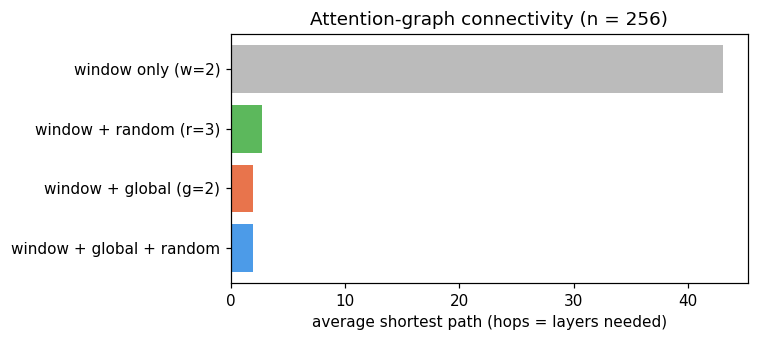

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
names = list(results)
ax.barh(names, [results[k][0] for k in names], color=["#bbb", "#5CB85C", "#E8744C", "#4C9BE8"])
ax.set_xlabel("average shortest path (hops = layers needed)")
ax.set_title(f"Attention-graph connectivity (n = {n})")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 5. Complexity comparison

| Model | Attention pattern | Time / memory per layer | Typical max length |
|---|---|---|---|
| **BERT** | Full | $O(n^2)$ | 512 |
| **Longformer** | Sliding window (optionally dilated) + task-specific global tokens | $O(n \cdot (w + g))$ | 4096 (LED: 16K) |
| **BigBird** | Sliding window + global + random | $O(n \cdot (w + g + r))$ | 4096+ |

For fixed $w, g, r$, both Longformer and BigBird are $O(n)$.

### BigBird vs. Longformer
Both are linear-time. They differ in design philosophy:

- **Longformer** relies on locality plus hand-chosen global tokens (for example, question tokens in QA).
- **BigBird** adds random edges, which gives it the theoretical guarantees above and extra long-range connectivity without requiring task-specific global-token design.
- Empirically the two are often close, and BigBird's advantage shows most on tasks needing wide-scale information mixing.

      n |    BERT (full) |   Longformer |      BigBird | speedup vs full
------------------------------------------------------------------------
    512 |        262,144 |      262,144 |      262,144 |            1.0x
   1024 |      1,048,576 |      524,288 |      524,288 |            2.0x
   2048 |      4,194,304 |    1,048,576 |    1,048,576 |            4.0x
   4096 |     16,777,216 |    2,097,152 |    2,097,152 |            8.0x
   8192 |     67,108,864 |    4,194,304 |    4,194,304 |           16.0x
  16384 |    268,435,456 |    8,388,608 |    8,388,608 |           32.0x
  32768 |  1,073,741,824 |   16,777,216 |   16,777,216 |           64.0x
  65536 |  4,294,967,296 |   33,554,432 |   33,554,432 |          128.0x


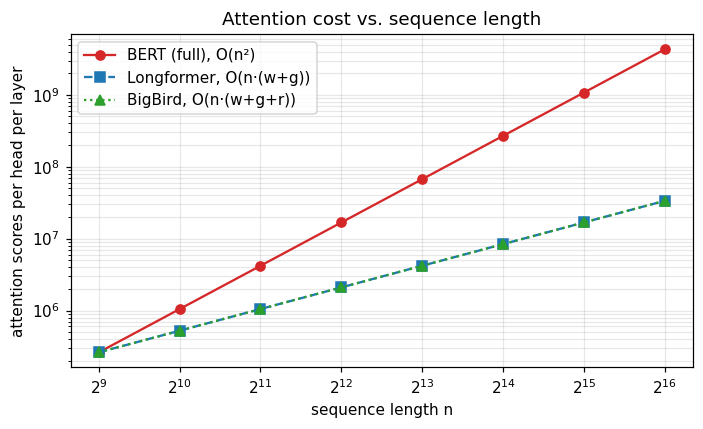

In [9]:
budget = 512  # keys per query for both sparse models (illustrative, matches the config above)

ns = np.array([512, 1024, 2048, 4096, 8192, 16384, 32768, 65536])
bert       = ns.astype(float) ** 2
longformer = ns * np.minimum(ns, budget)   # window + a few globals, ~512 keys/query
bigbird    = ns * np.minimum(ns, budget)   # window + global + random, ~512 keys/query

print(f"{'n':>7} | {'BERT (full)':>14} | {'Longformer':>12} | {'BigBird':>12} | {'speedup vs full':>15}")
print("-" * 72)
for i, n_ in enumerate(ns):
    print(f"{n_:>7} | {bert[i]:>14,.0f} | {longformer[i]:>12,.0f} | {bigbird[i]:>12,.0f} | {bert[i]/bigbird[i]:>14.1f}x")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(ns, bert, "o-", label="BERT (full), O(n²)", color="tab:red")
ax.plot(ns, longformer, "s--", label="Longformer, O(n·(w+g))", color="tab:blue")
ax.plot(ns, bigbird, "^:", label="BigBird, O(n·(w+g+r))", color="tab:green")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("sequence length n"); ax.set_ylabel("attention scores per head per layer")
ax.set_title("Attention cost vs. sequence length")
ax.grid(True, which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

> **Reading the plot.** With an equal per-token budget, Longformer and BigBird have the same asymptotic cost, so their curves coincide here. The difference between them is *which* 512 keys each query sees, not how many. Below roughly 512 to 1K tokens there is no saving, because the sparse patterns cover (nearly) the whole sequence anyway.

## 6. Suitable applications

BigBird fits tasks where the relevant information is spread across thousands of tokens:

- **Long-document QA and multi-hop reasoning** (HotpotQA, Natural Questions, TriviaQA, WikiHop), where evidence sits in different parts of a document.
- **Long-document summarization**, using BigBird as the encoder in a Pegasus-style encoder-decoder (arXiv, PubMed, BigPatent). The decoder is short, so it can keep full attention.
- **Long-document classification**, such as patents, scientific papers, legal contracts, and clinical notes.
- **Genomics:** DNA sequences are very long, and BigBird has shown strong results on promoter-region and chromatin-profile prediction.
- **Retrieval and reranking** over long passages or full documents.

The original models were pretrained with masked language modeling on Books, CC-News, Stories, and Wikipedia, initialized from RoBERTa checkpoints. They set state-of-the-art results on several QA and summarization benchmarks at the time of publication.

## 7. Advantages, limitations, and performance

### Advantages
- Linear time and memory in sequence length, so about 8x longer inputs on similar hardware.
- Theoretical backing: universal approximation and Turing completeness.
- Strong results on long-context QA, summarization, and genomics.
- Block-sparse design makes it efficient on modern accelerators.
- Can reuse existing pretrained checkpoints (such as RoBERTa) as a starting point.

### Limitations
- **Context is still bounded.** 4096 tokens is much more than 512, but it is not unlimited. Very long inputs (books, entire codebases) still need other strategies.
- **No savings on short inputs.** Overhead from block bookkeeping means gains appear mainly beyond roughly 1 to 2K tokens. Implementations such as Hugging Face's fall back to full attention for short sequences.
- **Fixed, content-independent patterns.** Random and window edges are not learned, so the model can miss a crucial distant token that neither a global nor random edge happens to connect.
- **Random attention is of debated value.** Ablations suggest it contributes modestly compared with window and global attention, and it is the hardest component to implement efficiently.
- **Sparse attention isn't equivalent to full attention.** The paper's own separation result shows some computations need more layers.
- **Practical constraints:** sequence lengths are padded to a multiple of the block size, extra hyperparameters (block size, number of random blocks, global-token choice) need tuning, and the original design is encoder-focused rather than suited to long autoregressive generation.

### Performance summary
BigBird matches or beats RoBERTa-style baselines on tasks that fit in 512 tokens, and gives clear gains where longer context matters. Compared with Longformer it is competitive, sometimes better, with the same asymptotic cost.

## 8. Using BigBird in practice (Hugging Face)


Task-specific variants include `BigBirdForQuestionAnswering`, `BigBirdForSequenceClassification`, and `BigBirdPegasusForConditionalGeneration` 


In [ ]:

from transformers import AutoTokenizer, BigBirdModel

tok = AutoTokenizer.from_pretrained("google/bigbird-roberta-base")
model = BigBirdModel.from_pretrained(
    "google/bigbird-roberta-base",
    attention_type="block_sparse",   # or "original_full" to compare
    block_size=64,
    num_random_blocks=3,
)

text = "your long document ... " * 500
inputs = tok(text, return_tensors="pt", truncation=True, max_length=4096)
outputs = model(**inputs)
print(outputs.last_hidden_state.shape)


## Summary

BigBird's key idea is that you don't need every token-to-token connection. A sparse graph combining local windows, a few global hubs, and random shortcuts keeps information flowing across the whole sequence while cutting complexity from $O(n^2)$ to $O(n)$. It trades a little flexibility for the ability to read long documents in one pass, which is why it became a standard choice for long-document NLP and genomics.

**Reference:** Zaheer et al., *Big Bird: Transformers for Longer Sequences*, NeurIPS 2020 (arXiv:2007.14062).